# Step 1：日本語の指示で動くROS 2 × Gazeboロボット

目的は、AIの予測から実際のシミュレーション走行までを自分で確認することです。
このNotebookは本プロジェクトのDocker内で動かします。Colabの通常ランタイムでは動作しません。

**構成**：日本語 → TF-IDF＋ロジスティック回帰 → 目的地 → ROS 2 `/cmd_vel` → Gazeboの車輪。
Gazeboの `/odom` を見ながら到着を判定します。この位置はOdometryPublisherによるシミュレータの実位置で、車輪からの推定値やSLAMではありません。走行制御は比例制御で、AIが学習するのは指示の分類です。
点検地点・備品地点は床の目印です。実際の点検や物品の取得、トイレ清掃は行いません。

In [1]:
from pathlib import Path
import os, sys, json, subprocess
ROOT = Path('/work')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT/'scripts'))
assert Path('/opt/ros/jazzy').exists(), '本プロジェクトのDockerで開いてください'
print('ROS 2 Jazzy / Gazebo Harmonic')

ROS 2 Jazzy / Gazebo Harmonic


## 1. AIの学習と確認
40文で4分類を学習します。別に用意した8文を確認します。小さな人工データであり、一般的な日本語の理解能力は評価していません。

In [2]:
from intent_model import train, predict
model = train()

{
  "training_examples": 40,
  "test_examples": 8,
  "correct": 8,
  "test": [
    {
      "text": "点検エリアへ移動してください",
      "expected": "inspection",
      "predicted": "inspection",
      "confidence": 0.8157344877359703
    },
    {
      "text": "点検地点で待って",
      "expected": "inspection",
      "predicted": "inspection",
      "confidence": 0.9479066997122907
    },
    {
      "text": "備品の場所まで進んでください",
      "expected": "supply",
      "predicted": "supply",
      "confidence": 0.7760288918868197
    },
    {
      "text": "備品エリアに行きたい",
      "expected": "supply",
      "predicted": "supply",
      "confidence": 0.9290687320198966
    },
    {
      "text": "ホームに戻ってください",
      "expected": "home",
      "predicted": "home",
      "confidence": 0.9057684001976174
    },
    {
      "text": "出発地点に帰りたい",
      "expected": "home",
      "predicted": "home",
      "confidence": 0.8892813480691507
    },
    {
      "text": "いったん停止してください",
      "expected": "stop",
      "predicted": "sto

## 2. 指示を変えてみる
分類スコア0.60未満は未対応として停止します。スコアは正しさを保証する確率ではありません。

In [3]:
instruction = '点検エリアへ移動してください'
intent, score = predict(model, instruction)
print(f'入力: {instruction} / 分類: {intent} / スコア: {score:.3f}')

入力: 点検エリアへ移動してください / 分類: inspection / スコア: 0.816


## 3. 実際にGazeboで走行・録画
以下を実行すると、点検 → 備品 → ホームの3地点を巡回します。所要時間は環境によりますが通常2分程度です。`output/demo.mp4` と走行ログは再実行時に更新されます。他のデモ実行中には開始できません。

In [4]:
result = subprocess.run(['bash','-lc','source /opt/ros/jazzy/setup.bash && python3 scripts/run_demo.py'], text=True, capture_output=True)
print(result.stdout)
print(result.stderr)
assert result.returncode == 0, 'logs/ を確認してください' 

/work/world/step1.sdf
{
  "training_examples": 40,
  "test_examples": 8,
  "correct": 8,
  "test": [
    {
      "text": "点検エリアへ移動してください",
      "expected": "inspection",
      "predicted": "inspection",
      "confidence": 0.8157344877359703
    },
    {
      "text": "点検地点で待って",
      "expected": "inspection",
      "predicted": "inspection",
      "confidence": 0.9479066997122907
    },
    {
      "text": "備品の場所まで進んでください",
      "expected": "supply",
      "predicted": "supply",
      "confidence": 0.7760288918868197
    },
    {
      "text": "備品エリアに行きたい",
      "expected": "supply",
      "predicted": "supply",
      "confidence": 0.9290687320198966
    },
    {
      "text": "ホームに戻ってください",
      "expected": "home",
      "predicted": "home",
      "confidence": 0.9057684001976174
    },
    {
      "text": "出発地点に帰りたい",
      "expected": "home",
      "predicted": "home",
      "confidence": 0.8892813480691507
    },
    {
      "text": "いったん停止してください",
      "expected": "stop",
 

## 4. 動画を見る
映像左側はGazeboの仮想カメラ画像、右側はROS 2で受信した座標とAIの結果です。

In [5]:
from IPython.display import Video, display
display(Video('output/demo.mp4', embed=True, width=960))

## 5. 到着誤差と走行軌跡
到着判定は10 cm未満です。障害物のない既知の環境での結果です。

{
  "success": true,
  "failure": null,
  "goals": [
    {
      "intent": "inspection",
      "position": [
        1.9002825253087916,
        2.234477026052134e-13
      ],
      "error_m": 0.0997174746912084
    },
    {
      "intent": "supply",
      "position": [
        1.9982571860281535,
        1.7013000365203734
      ],
      "error_m": 0.09871534932025562
    },
    {
      "intent": "home",
      "position": [
        0.07373796808886321,
        0.0662063035550831
      ],
      "error_m": 0.09909875159810046
    }
  ],
  "events": [
    {
      "time": 0.0,
      "event": "recording_started"
    },
    {
      "time": 8.052,
      "event": "instruction",
      "text": "点検エリアへ移動してください",
      "intent": "inspection",
      "confidence": 0.8157344877359703,
      "goal": [
        2.0,
        0.0
      ]
    },
    {
      "time": 16.801,
      "event": "arrived",
      "intent": "inspection",
      "position": [
        1.9002825253087916,
        2.234477026052134e-13


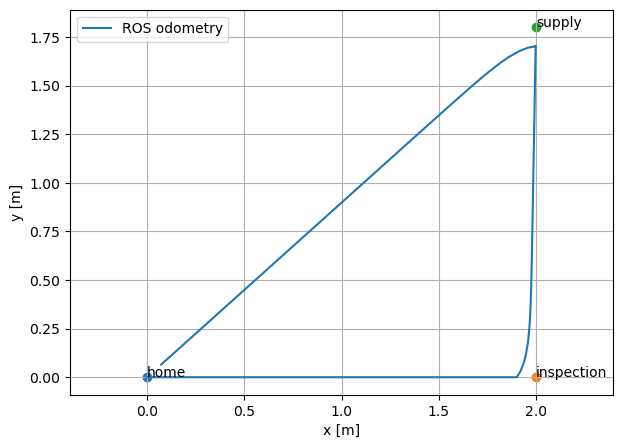

In [6]:
run = json.loads(Path('output/run_result.json').read_text())
print(json.dumps(run, ensure_ascii=False, indent=2))
assert run['success']
import csv
import matplotlib.pyplot as plt
with open('output/trajectory.csv') as f:
    rows = list(csv.DictReader(f))
plt.figure(figsize=(7,5))
plt.plot([float(r['x']) for r in rows], [float(r['y']) for r in rows], label='ROS odometry')
for label,(x,y) in {'home':(0,0),'inspection':(2,0),'supply':(2,1.8)}.items():
    plt.scatter(x,y); plt.annotate(label,(x,y))
plt.axis('equal'); plt.grid(); plt.legend(); plt.xlabel('x [m]'); plt.ylabel('y [m]'); plt.show()

## 次に理解しておくこと

- `scripts/intent_model.py`：日本語を分類するAI。学習用の文と評価用の文は別です。
- `scripts/controller.py`：AI分類、ROSトピック、到着判定、停止、録画。
- `world/step1.sdf`：物理的なロボットモデルとシミュレーション環境。
- `config/bridge.yaml`：ROS 2とGazeboの通信を接続。

Step 2では、指示の言い換え・速度・目的地を一つずつ変え、成功率や誤差を比べます。
Step 3では、トイレ清掃をいきなり全部作らず、床の走行範囲や障害物回避など一点に絞ります。

提出の前にREADMEのチェックリストを確認してください。